### Model 3 - Context of Possession 
The third models will build upon the geometric information used in the first models, and the contextual information about the pass in the second models, to include contextual information about the current state of possession:
- how many passes in the possession so far?
- how far was the ball carried before the pass?
- how fast has the ball moved vertically up the pitch in the previous three actions?
- was the previous action by a teammate or an opponent?
- what was the distance and angle of the previous pass?

We will train both a logisitc regressor and Gradient Booster on the same data and comapre their results.

In [4]:
# -------------------------------------------
# 1. Load the passing data
# -------------------------------------------
import pandas as pd
from pathlib import Path

passes_df = pd.read_csv(Path.cwd().parent / "data/cleaned/xPass_features.csv")

In [30]:
# -------------------------------------------
# 2. Define training and target features 
# -------------------------------------------
features = ["x",
            "y",
            "end_x",
            "end_y",
            "pass_length",
            "pass_angle_sin",
            "pass_angle_cos",
            "is_head_pass",
            "is_cross",
            "is_set_piece",
            "is_chipped",
            "passes_in_possession",
            "previous_action_same_team"]

X = passes_df[features].copy()
y = passes_df["outcome"].copy()
groups = passes_df["game_id"].copy()

print("Missing features:", X.isna().sum().sum())
print("Missing targets:", y.isna().sum())
print("Unique matches:", groups.nunique())
print("Total passes:", len(X))

Missing features: 0
Missing targets: 0
Unique matches: 1752
Total passes: 1689005


In [32]:
# -------------------------------------------
# 3. Split test and train data
# -------------------------------------------
from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(n_splits = 1,
                             test_size = 0.2,
                             random_state = 42)

train_idx, test_idx = next(splitter.split(X,
                                          y,
                                          groups = groups))
X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

print("Training passes:", len(X_train))
print("Testing passes:", len(X_test))

print("Training matches:", groups.iloc[train_idx].nunique())
print("Testing matches:", groups.iloc[test_idx].nunique())

Training passes: 1348272
Testing passes: 340733
Training matches: 1401
Testing matches: 351


### Logistic Regressor

In [34]:
# -------------------------------------------
# 4. Train and predict
# -------------------------------------------

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    log_loss,
    brier_score_loss
)

LR_model = make_pipeline(StandardScaler(),
                        LogisticRegression(max_iter = 1000))

LR_model.fit(X_train, y_train)

LR_proba = LR_model.predict_proba(X_test)[:, 1]
LR_pred = (LR_proba >= 0.5).astype(int)

print(f"Accuracy:  {accuracy_score(y_test, LR_pred):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, LR_proba):.4f}")
print(f"Log Loss:  {log_loss(y_test, LR_proba):.4f}")
print(f"Brier:     {brier_score_loss(y_test, LR_proba):.4f}")

Accuracy:  0.8556
ROC-AUC:   0.8593
Log Loss:  0.3401
Brier:     0.1052


In [36]:
# -------------------------------------------
# 5. Check feature importance
# -------------------------------------------

lr_importance = pd.DataFrame({
    "feature": X_train.columns,
    "coefficient": LR_model.named_steps["logisticregression"].coef_[0]
})

lr_importance["abs_coefficient"] = (
    lr_importance["coefficient"].abs()
)

lr_importance = lr_importance.sort_values(
    "abs_coefficient",
    ascending=False
)

display(lr_importance)

,feature,coefficient,abs_coefficient
2,end_x,-3.030033,3.030033
0,x,2.559212,2.559212
4,pass_length,0.759938,0.759938
8,is_cross,-0.566858,0.566858
7,is_head_pass,-0.315361,0.315361
10,is_chipped,-0.267624,0.267624
11,passes_in_possession,0.218216,0.218216
6,pass_angle_cos,0.177355,0.177355
12,previous_action_same_team,0.135107,0.135107
9,is_set_piece,0.124932,0.124932


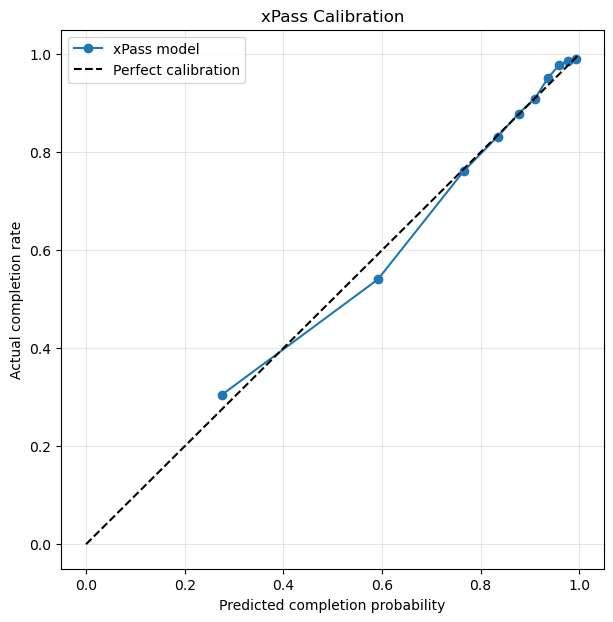

,mean_predicted,actual_completion,pass_count,difference
probability_bin,,,,
"(0.016, 0.452]",0.275977,0.305423,34074,0.029447
"(0.452, 0.71]",0.591796,0.540545,34073,-0.051251
"(0.71, 0.807]",0.766037,0.761864,34073,-0.004173
"(0.807, 0.858]",0.834456,0.831920,34073,-0.002536
"(0.858, 0.895]",0.877220,0.878969,34074,0.001749
"(0.895, 0.924]",0.909676,0.909195,34073,-0.000481
"(0.924, 0.949]",0.937313,0.952396,34073,0.015084
"(0.949, 0.969]",0.959475,0.978194,34073,0.018719
"(0.969, 0.985]",0.977255,0.985795,34073,0.008540


In [13]:
# -------------------------------------------
# 6. Check Calibration
# -------------------------------------------

from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

prob_true, prob_pred = calibration_curve(
    y_test,
    LR_proba,
    n_bins=10,
    strategy="quantile"
)

fig, ax = plt.subplots(figsize=(7, 7))

ax.plot(prob_pred, prob_true, marker="o", label="xPass model")
ax.plot([0, 1], [0, 1], linestyle="--", color="black", label="Perfect calibration")

ax.set_xlabel("Predicted completion probability")
ax.set_ylabel("Actual completion rate")
ax.set_title("xPass Calibration")
ax.legend()
ax.grid(alpha=0.3)

plt.show()

calibration_df = pd.DataFrame({
    "predicted": LR_proba,
    "actual": y_test.values
})

calibration_df["probability_bin"] = pd.qcut(
    calibration_df["predicted"],
    q=10,
    duplicates="drop"
)

calibration_summary = calibration_df.groupby(
    "probability_bin",
    observed=True
).agg(
    mean_predicted=("predicted", "mean"),
    actual_completion=("actual", "mean"),
    pass_count=("actual", "size")
)

calibration_summary["difference"] = (
    calibration_summary["actual_completion"]
    - calibration_summary["mean_predicted"]
)

display(calibration_summary)

### Gradient Booster

In [40]:
# -------------------------------------------
# 7. Train a Gradient Boosting model A
# -------------------------------------------
from sklearn.ensemble import HistGradientBoostingClassifier

GB_model_A = HistGradientBoostingClassifier(
    max_iter=200,
    learning_rate=0.1,
    max_leaf_nodes=15,
    l2_regularization=1.0,
    random_state=42,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=10
)

GB_model_A.fit(X_train, y_train)

GB_proba_A = GB_model_A.predict_proba(X_test)[:, 1]
GB_pred_A = (GB_proba >= 0.5).astype(int)

print(f"Accuracy:  {accuracy_score(y_test, GB_pred_A):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, GB_proba_A):.4f}")
print(f"Log Loss:  {log_loss(y_test, GB_proba_A):.4f}")
print(f"Brier:     {brier_score_loss(y_test, GB_proba_A):.4f}")

Accuracy:  0.8913
ROC-AUC:   0.9265
Log Loss:  0.2543
Brier:     0.0779


In [42]:
# -------------------------------------------
# 8. Evaluate feature importance of Model A
# -------------------------------------------

from sklearn.inspection import permutation_importance

gb_importance = permutation_importance(
    GB_model_A,
    X_test,
    y_test,
    scoring="neg_log_loss",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "feature": X_test.columns,
    "importance": gb_importance.importances_mean,
    "std": gb_importance.importances_std
})

importance_df = importance_df.sort_values(
    "importance",
    ascending=False
)

display(importance_df)

,feature,importance,std
4,pass_length,0.104489,0.000283
6,pass_angle_cos,0.090122,0.000418
2,end_x,0.077605,0.000290
3,end_y,0.063421,0.000720
7,is_head_pass,0.018553,0.000124
10,is_chipped,0.011728,0.000123
1,y,0.008186,0.000066
9,is_set_piece,0.007798,0.000131
8,is_cross,0.007665,0.000119
5,pass_angle_sin,0.006476,0.000090


In [6]:
# -------------------------------------------
# 9. Define training and target features for MODEL B
# -------------------------------------------
features = ["x",
            "y",
            "end_x",
            "end_y",
            "pass_length",
            "pass_angle_sin",
            "pass_angle_cos",
            "is_head_pass",
            "is_cross",
            "is_set_piece",
            "is_chipped",
            "passes_in_possession",
            "previous_action_same_team",
            "previous_pass_length",
            "previous_pass_angle_sin",
            "previous_pass_angle_cos"]

X = passes_df[features].copy()
y = passes_df["outcome"].copy()
groups = passes_df["game_id"].copy()

print("Missing features:", X.isna().sum().sum())
print("Missing targets:", y.isna().sum())
print("Unique matches:", groups.nunique())
print("Total passes:", len(X))

# -------------------------------------------
# 10. Split test and train data
# -------------------------------------------
from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(n_splits = 1,
                             test_size = 0.2,
                             random_state = 42)

train_idx, test_idx = next(splitter.split(X,
                                          y,
                                          groups = groups))
X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

print("Training passes:", len(X_train))
print("Testing passes:", len(X_test))

print("Training matches:", groups.iloc[train_idx].nunique())
print("Testing matches:", groups.iloc[test_idx].nunique())

Missing features: 1293009
Missing targets: 0
Unique matches: 1752
Total passes: 1689005
Training passes: 1348272
Testing passes: 340733
Training matches: 1401
Testing matches: 351


In [12]:
# -------------------------------------------
# 11. Train a Gradient Boosting model B
# -------------------------------------------
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    log_loss,
    brier_score_loss
)
GB_model_B = HistGradientBoostingClassifier(
    max_iter=200,
    learning_rate=0.1,
    max_leaf_nodes=15,
    l2_regularization=1.0,
    random_state=42,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=10
)

GB_model_B.fit(X_train, y_train)

GB_proba_B = GB_model_B.predict_proba(X_test)[:, 1]
GB_pred_B = (GB_proba_B >= 0.5).astype(int)

print(f"Accuracy:  {accuracy_score(y_test, GB_pred_B):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, GB_proba_B):.4f}")
print(f"Log Loss:  {log_loss(y_test, GB_proba_B):.4f}")
print(f"Brier:     {brier_score_loss(y_test, GB_proba_B):.4f}")

Accuracy:  0.8916
ROC-AUC:   0.9302
Log Loss:  0.2501
Brier:     0.0772


In [14]:
# -------------------------------------------
# 12. Evaluate feature importance of Model B
# -------------------------------------------

from sklearn.inspection import permutation_importance

gb_importance = permutation_importance(
    GB_model_B,
    X_test,
    y_test,
    scoring="neg_log_loss",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "feature": X_test.columns,
    "importance": gb_importance.importances_mean,
    "std": gb_importance.importances_std
})

importance_df = importance_df.sort_values(
    "importance",
    ascending=False
)

display(importance_df)

,feature,importance,std
4,pass_length,0.102988,0.000190
6,pass_angle_cos,0.097694,0.000381
2,end_x,0.064290,0.000330
3,end_y,0.059307,0.000684
7,is_head_pass,0.013392,0.000112
10,is_chipped,0.010680,0.000108
15,previous_pass_angle_cos,0.010069,0.000134
5,pass_angle_sin,0.008315,0.000100
9,is_set_piece,0.007419,0.000123
1,y,0.007275,0.000079


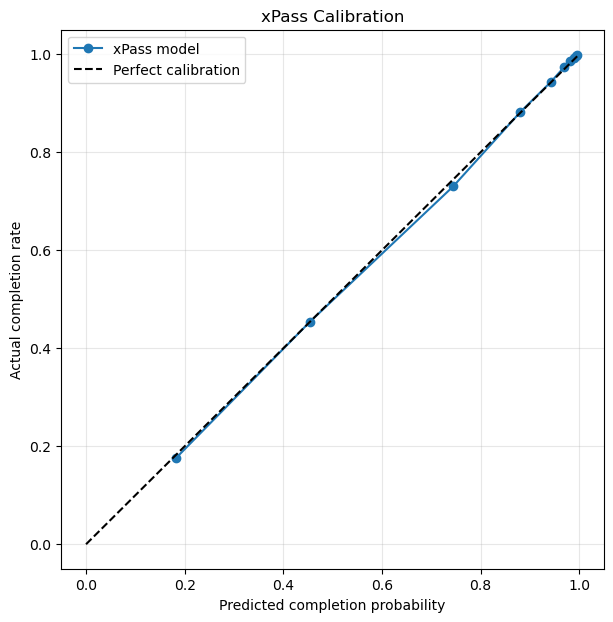

,mean_predicted,actual_completion,pass_count,difference
probability_bin,,,,
"(-0.0005920000000000001, 0.314]",0.181630,0.175119,34074,-0.006511
"(0.314, 0.618]",0.453496,0.453556,34073,0.000060
"(0.618, 0.831]",0.744405,0.730256,34073,-0.014149
"(0.831, 0.92]",0.880751,0.882253,34073,0.001501
"(0.92, 0.96]",0.942631,0.943593,34074,0.000962
"(0.96, 0.977]",0.969505,0.974026,34073,0.004521
"(0.977, 0.986]",0.982227,0.986705,34073,0.004478
"(0.986, 0.992]",0.989287,0.993103,34073,0.003816
"(0.992, 0.995]",0.993336,0.997124,34073,0.003787


In [16]:
# -------------------------------------------
# 6. Check Calibration of GB Model B
# -------------------------------------------

from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

prob_true, prob_pred = calibration_curve(
    y_test,
    GB_proba_B,
    n_bins=10,
    strategy="quantile"
)

fig, ax = plt.subplots(figsize=(7, 7))

ax.plot(prob_pred, prob_true, marker="o", label="xPass model")
ax.plot([0, 1], [0, 1], linestyle="--", color="black", label="Perfect calibration")

ax.set_xlabel("Predicted completion probability")
ax.set_ylabel("Actual completion rate")
ax.set_title("xPass Calibration")
ax.legend()
ax.grid(alpha=0.3)

plt.show()

calibration_df = pd.DataFrame({
    "predicted": GB_proba_B,
    "actual": y_test.values
})

calibration_df["probability_bin"] = pd.qcut(
    calibration_df["predicted"],
    q=10,
    duplicates="drop"
)

calibration_summary = calibration_df.groupby(
    "probability_bin",
    observed=True
).agg(
    mean_predicted=("predicted", "mean"),
    actual_completion=("actual", "mean"),
    pass_count=("actual", "size")
)

calibration_summary["difference"] = (
    calibration_summary["actual_completion"]
    - calibration_summary["mean_predicted"]
)

display(calibration_summary)

### Calibration per League

In [69]:
# Match each held-out prediction to its league and actual outcome
import numpy as np

test_results = passes_df.iloc[test_idx][["league"]].copy()

test_results["actual"] = np.asarray(y_test)
test_results["predicted"] = GB_proba_B

test_results.head()

,league,actual,predicted
1095,bundesliga,1,0.990199
1096,bundesliga,1,0.686088
1097,bundesliga,1,0.153615
1098,bundesliga,1,0.232705
1099,bundesliga,0,0.838024


In [71]:
from sklearn.metrics import brier_score_loss, log_loss, roc_auc_score

league_metrics = []

for league, group in test_results.groupby("league"):

    actual = group["actual"]
    predicted = group["predicted"]

    league_metrics.append({
        "league": league,
        "pass_count": len(group),
        "completion_rate": actual.mean(),
        "mean_predicted": predicted.mean(),
        "brier_score": brier_score_loss(actual, predicted),
        "log_loss": log_loss(actual, predicted),
        "roc_auc": roc_auc_score(actual, predicted)
    })

league_metrics = pd.DataFrame(league_metrics)

league_metrics.sort_values("brier_score")

,league,pass_count,completion_rate,mean_predicted,brier_score,log_loss,roc_auc
2,ligue1,62352,0.824144,0.823002,0.074779,0.244678,0.928178
1,la-liga,69428,0.820577,0.820044,0.075670,0.247065,0.928431
3,prem,83069,0.805800,0.807140,0.076399,0.248229,0.934227
4,serie-a,69185,0.809424,0.808436,0.078717,0.252026,0.931264
0,bundesliga,56699,0.809203,0.809756,0.081169,0.260452,0.926075


### Full Predictions

In [101]:
# Fit final GB model on the entire dataset
GB_model_B.fit(X, y)

,"loss loss: {'log_loss'}, default='log_loss'The loss function to use in the boosting process.For binary classification problems, 'log_loss' is also known as logistic loss,binomial deviance or binary crossentropy. Internally, the model fits one treeper boosting iteration and uses the logistic sigmoid function (expit) asinverse link function to compute the predicted positive class probability.For multiclass classification problems, 'log_loss' is also known as multinomialdeviance or categorical crossentropy. Internally, the model fits one tree perboosting iteration and per class and uses the softmax function as inverse linkfunction to compute the predicted probabilities of the classes.",'log_loss'
,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.1
,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees for binary classification. For multiclassclassification, `n_classes` trees per iteration are built.",200
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",15
,"max_depth max_depth: int or None, default=NoneThe maximum depth of each tree. The depth of a tree is the number ofedges to go from the root to the deepest leaf.Depth isn't constrained by default.",None
,"min_samples_leaf min_samples_leaf: int, default=20The minimum number of samples per leaf. For small datasets with lessthan a few hundred samples, it is recommended to lower this valuesince only very shallow trees would be built.",20
,"l2_regularization l2_regularization: float, default=0The L2 regularization parameter penalizing leaves with small hessians.Use ``0`` for no regularization (default).",1.0
,"max_features max_features: float, default=1.0Proportion of randomly chosen features in each and every node split.This is a form of regularization, smaller values make the trees weakerlearners and might prevent overfitting.If interaction constraints from `interaction_cst` are present, only allowedfeatures are taken into account for the subsampling... versionadded:: 1.4",1.0
,"max_bins max_bins: int, default=255The maximum number of bins to use for non-missing values. Beforetraining, each feature of the input array `X` is binned intointeger-valued bins, which allows for a much faster training stage.Features with a small number of unique values may use less than``max_bins`` bins. In addition to the ``max_bins`` bins, one more binis always reserved for missing values. Must be no larger than 255.",255
,"categorical_features categorical_features: array-like of {bool, int, str} of shape (n_features) or shape (n_categorical_features,), default='from_dtype'Indicates the categorical features.- None : no feature will be considered categorical.- boolean array-like : boolean mask indicating categorical features.- integer array-like : integer indices indicating categorical features.- str array-like: names of categorical features (assuming the training data has feature names).- `""from_dtype""`: dataframe columns with dtype ""category"" are considered to be categorical features. The input must be an object exposing a ``__dataframe__`` method such as pandas or polars DataFrames to use this feature.For each categorical feature, there must be at most `max_bins` uniquecategories. Negative values for categorical features encoded as numericdtypes are treated as missing values. All categorical values areconverted to floating point numbers. This means that categorical valuesof 1.0 and 1 are treated as the same category.Read more in the :ref:`User Guide `... versionadded:: 0.24.. versionchanged:: 1.2 Added support for feature names... versionchanged:: 1.4 Added `""from_dtype""` option... versionchanged:: 1.6 The default value changed from `None` to `""from_dtype""`.",'from_dt

In [103]:
# Predict probability of successful completion
passes_df['xPass'] = GB_model_B.predict_proba(X)[:, 1]

In [105]:
passes_df["PAx"] = passes_df["outcome"] - passes_df["xPass"]

In [109]:
xPass_cols = ["game_id",
              "player_id",
              "player",
              "minute",
              "second",
              "x",
              "y",
              "end_x",
              "end_y",
              "outcome",
              "xPass",
              "PAx"]
xpass_df = passes_df[xPass_cols]

xpass_df.to_csv(Path.cwd().parent / "data/cleaned/xPass.csv", index = False)

In [22]:
# -------------------------------------------
# 6. Export the final model
# -------------------------------------------
import joblib

joblib.dump(GB_model_B, Path.cwd().parent / "model/xpass_gb_model.pkl")
joblib.dump(features, Path.cwd().parent /"model/xpass_features.pkl")

['/Users/Seth/Desktop/Football Analyses/xPass/model/xpass_features.pkl']